# Calculus of variations 2: Hanging chains and soap films

*Learning path: calculus of variations, part 2 of 3.* [Index](README.md) · Previous: [Shortest paths and the fastest slide](01-shortest-paths-and-the-fastest-slide.ipynb) · Next: [The principle of least action](03-the-principle-of-least-action.ipynb)

Dip two wire rings in soapy water, hold them face to face and pull them apart: a soap film stretches between them,
narrow in the middle like the waist of an hourglass. Hang a chain between two hooks and it sags into a smooth curve.
Galileo Galilei thought the hanging chain was a parabola; in 1691 Leibniz, Huygens and Johann Bernoulli showed that it
is not. Both shapes are the same curve, the **catenary** (from the Latin *catena*, chain), and both come from the
same principle: nature makes something as small as it can. The soap film makes its area as small as possible
(surface tension), the chain its height, and so its potential energy, as low as possible.

This lesson also shows two new things: problems with a **constraint** (a chain of given length, a fence of given
length), solved with a Lagrange multiplier, and a problem where the smooth answer suddenly stops existing.

**Who this is for.** Students who have done [lesson 1](01-shortest-paths-and-the-fastest-slide.ipynb).

**What you will be able to do afterwards:**

1. set up the area of a surface of revolution and the energy of a chain as functionals;
2. find the catenary from the conserved quantity `energy`;
3. explain why a soap film between rings can snap, and when no smooth film exists;
4. solve problems with a constraint by adding a multiplier $\lambda$ to the Lagrangian;
5. solve Dido's problem: the largest area for a given length of fence.

Plan about 50 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. A soap film between two rings

Put two rings of radius $R$ at $x = -1$ and $x = 1$, both centred on the $x$-axis. The film between them is a surface
of revolution: the curve $y(x)$ turned around the axis. Each slice of length $ds = \sqrt{1 + y'^2}\,dx$ sweeps out a band
of area $2\pi y\, ds$, so the area is

$$A[y] = \int_{-1}^{1} 2\pi\, y \sqrt{1 + y'^2}\; dx.$$

Its Euler–Lagrange equation:

In [1]:
eulerlagrange(y*sqrt(1 + d(y, x)^2), y, x)

d(y, x, 2) == (d(y, x)^2+1)/y

> Euler–Lagrange equation: d/dx(dL/dy') = dL/dy. A path that makes the integral of L smallest (or stationary) with fixed end points satisfies it. The equations are solved for the second derivatives. L does not contain x itself, so energy(L, ...) = -y/sqrt(d(y, x)^2+1) stays constant along every extremal (Beltrami's identity, conservation of energy).

$L$ does not contain $x$, so the energy (Beltrami's identity from lesson 1) is constant:

In [2]:
energy(y*sqrt(1 + d(y, x)^2), y, x)

-y/sqrt(d(y, x)^2+1)

> E = y' dL/dy' - L, the sum of q' dL/dq' over the unknowns minus L. When L does not contain x itself, E is constant along every solution of the Euler–Lagrange equations: in mechanics it is the total energy, in geometry Beltrami's first integral.

So $y/\sqrt{1 + y'^2} = c$, a constant. The function $y = c\cosh(x/c)$ solves it: its slope is $\sinh(x/c)$, and since
$1 + \sinh^2 = \cosh^2$, $y/\sqrt{1 + y'^2} = c\cosh(x/c)/\cosh(x/c) = c$. This is the **catenary**, and the surface
it sweeps out is the **catenoid**. To fit rings of radius $R = 2$ we need $c\cosh(1/c) = 2$:

In [3]:
fsolve(c*cosh(1/c) - 2, c, 2)
fsolve(c*cosh(1/c) - 2, c, 0.3)

1.696675876189958

> `fsolve`: A numeric solution of f = 0 near the guess (Newton's method); for a system, Newton's method with the Jacobian.

0.4701899804690654

> `fsolve`: A numeric solution of f = 0 near the guess (Newton's method); for a system, Newton's method with the Jacobian.

Two catenaries fit, a fat one ($c \approx 1.70$) and a thin one ($c \approx 0.47$). Compare their areas with a third
option: no film between the rings at all, just two flat discs filling them, area $2\pi R^2$:

In [4]:
eval(action(2*pi*y*sqrt(1 + d(y, x)^2), y, x, 1.6967*cosh(x/1.6967), -1, 1), 4)
eval(action(2*pi*y*sqrt(1 + d(y, x)^2), y, x, 0.4702*cosh(x/0.4702), -1, 1), 4)
eval(2*pi*2^2, 4)

23.97

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

27.38

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

25.13

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The fat catenoid has the smallest area; it is the film you see. The thin one is also a solution of the Euler–Lagrange
equation, but a saddle: bend it slightly and its area goes down. `extremal` finds the fat one directly:

23.97

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

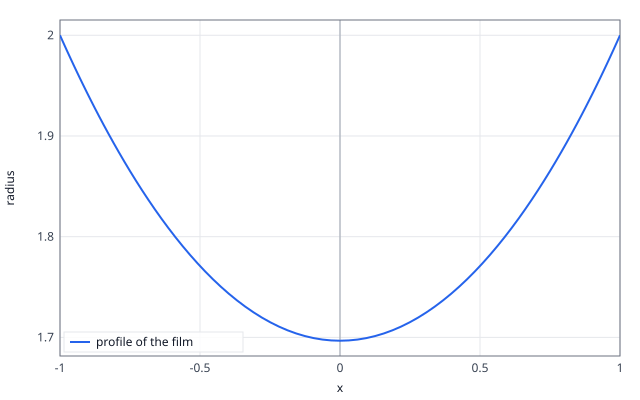

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
s = extremal(2*pi*y*sqrt(1 + d(y, x)^2), y, x, -1, 1, 2, 2);
eval(s.J, 4)
labels(legend(plot(s.x, s.y), "profile of the film"), "x", "radius")

**Try this.** Check that the fat catenary satisfies the conservation law: compute $y/\sqrt{1 + y'^2}$ for
$y = 1.6967\cosh(x/1.6967)$ at a few points, for example with `eval(...)` after substituting numbers for $x$.

## 2. When the film snaps

Pull the rings further apart, or make them smaller. In units where the rings are at $\pm 1$, a catenary fits only if
$c\cosh(1/c) = R$ has a solution. The left side has a smallest value:

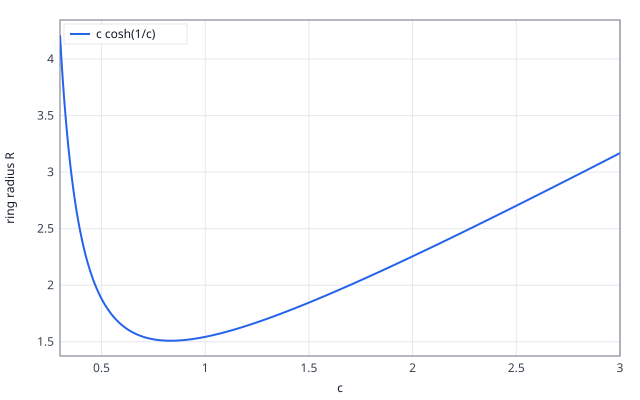

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
labels(legend(plot(c*cosh(1/c), c, 0.3, 3), "c cosh(1/c)"), "c", "ring radius R")

Its minimum is where the derivative $\cosh(1/c) - \sinh(1/c)/c$ is zero, that is $\tanh(1/c) = c$:

In [7]:
cm = fsolve(tanh(1/c) - c, c, 0.8)
eval(cm*cosh(1/cm), 5)

0.8335565596009648

> `fsolve`: A numeric solution of f = 0 near the guess (Newton's method); for a system, Newton's method with the Jacobian.

1.5089

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

For rings of radius below $1.5089$ (times the half-distance) there is **no catenoid at all**. A real soap film
stretched further than that snaps, and the soap ends up as two flat discs, one in each ring (the **Goldschmidt
solution**, found by Benjamin Goldschmidt in 1831). It has corners where the film meets the rings, so it is not a smooth
curve, and the Euler–Lagrange equation cannot see it. Asked for a film between rings of radius 1.4,
`extremal(y*sqrt(1 + d(y, x)^2), y, x, -1, 1, 1.4, 1.4)` reports that its search ran off and that no smooth path makes
the area stationary.

Even before that point the film is in danger. For $R = 1.6$ a catenoid exists, but its area is *larger* than the two
discs:

In [8]:
c4 = fsolve(c*cosh(1/c) - 1.6, c, 1.2)
eval(action(2*pi*y*sqrt(1 + d(y, x)^2), y, x, c4*cosh(x/c4), -1, 1), 4)
eval(2*pi*1.6^2, 4)

1.1259735166179528

> `fsolve`: A numeric solution of f = 0 near the guess (Newton's method); for a system, Newton's method with the Jacobian.

18.50

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

16.08

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The film is then only a *local* minimum: it survives small shakes, but a big enough disturbance pops it. The
calculus of variations only finds paths that are best compared with their *neighbours*.

**Try this.** For which ring radius $R$ do the fat catenoid and the two discs have the same area? Try a few values
between 1.6 and 2 with `fsolve` and `action`.

## 3. The hanging chain: a constraint

A chain of length 3 hangs from hooks at $(-1, 0)$ and $(1, 0)$. It settles where its potential energy, proportional to
$\int y\, ds = \int y\sqrt{1 + y'^2}\,dx$, is lowest. But not every curve is allowed: its length
$\int \sqrt{1 + y'^2}\,dx$ must be 3. Without that constraint the chain would sag to minus infinity.

Lagrange's trick for constraints: add the constraint with an unknown multiplier $\lambda$ and look for the extremals of
$\int (y + \lambda)\sqrt{1 + y'^2}\,dx$ without constraint. Then choose $\lambda$ (and the other constants) so the length
comes out right.

In [9]:
eulerlagrange((y + lam)*sqrt(1 + d(y, x)^2), y, x)

d(y, x, 2) == (d(y, x)^2+1)/(lam+y)

> Euler–Lagrange equation: d/dx(dL/dy') = dL/dy. A path that makes the integral of L smallest (or stationary) with fixed end points satisfies it. The equations are solved for the second derivatives. L does not contain x itself, so energy(L, ...) = -(lam+y)/sqrt(d(y, x)^2+1) stays constant along every extremal (Beltrami's identity, conservation of energy).

This is the soap-film equation for $y + \lambda$ instead of $y$: the chain is a catenary again,
$y = c\cosh(x/c) - \lambda$, shifted down. Its length from $-1$ to $1$ is $2c\sinh(1/c)$, which must be 3:

In [10]:
k = fsolve(2*c*sinh(1/c) - 3, c, 1)
eval(action(sqrt(1 + d(y, x)^2), y, x, k*cosh(x/k), -1, 1), 6)

0.6164729394720807

> `fsolve`: A numeric solution of f = 0 near the guess (Newton's method); for a system, Newton's method with the Jacobian.

3.00000

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The chain hangs as $y = k\cosh(x/k) - k\cosh(1/k)$, which is 0 at the hooks. Here it is next to a parabola that sags
just as deep:

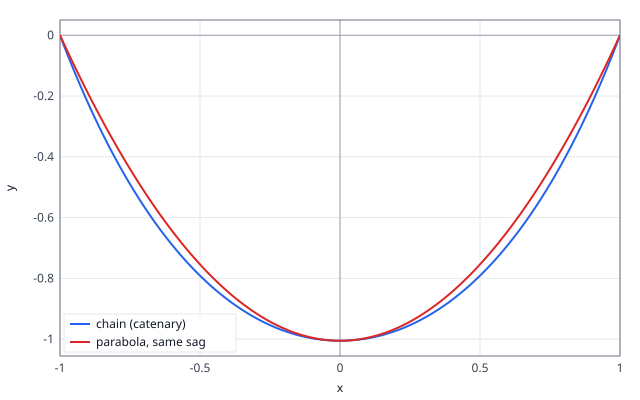

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
sag = k*cosh(1/k) - k;
p = legend(plot(k*cosh(x/k) - k*cosh(1/k), x, -1, 1), "chain (catenary)");
p = show(p, legend(plot(sag*(x^2 - 1), x, -1, 1), "parabola, same sag"));
labels(p, "x", "y")

Close, but not the same: Galileo's guess was a good approximation for shallow chains. Turned upside down, the catenary
is the ideal shape for an arch that carries only its own weight, pure compression with no bending, which is why
Robert Hooke wrote in 1675 "as hangs the flexible line, so but inverted will stand the rigid arch". The Gateway Arch in
St. Louis is a (slightly flattened) catenary.

**Try this.** How long is the parabola with the same sag? Use `action(sqrt(1 + d(y, x)^2), y, x, sag*(x^2 - 1), -1, 1)`.

## 4. Dido's problem

According to Virgil, the princess Dido fled to North Africa and was offered as much land as an ox hide could enclose.
She cut the hide into a thin strip and laid it in a curve against the coast, enclosing the city of Carthage. Which
curve of given length encloses the most area against a straight coast?

Take the coast as the $x$-axis and the strip as a curve $y(x)$ from $(-1, 0)$ to $(1, 0)$. Maximise the area
$\int y\,dx$ with the length $\int \sqrt{1 + y'^2}\,dx$ fixed. With a multiplier:

In [12]:
eulerlagrange(y + lam*sqrt(1 + d(y, x)^2), y, x)

d(y, x, 2) == (d(y, x)^2+1)^(3/2)/lam

> Euler–Lagrange equation: d/dx(dL/dy') = dL/dy. A path that makes the integral of L smallest (or stationary) with fixed end points satisfies it. The equations are solved for the second derivatives. L does not contain x itself, so energy(L, ...) = -(lam+y*sqrt(d(y, x)^2+1))/sqrt(d(y, x)^2+1) stays constant along every extremal (Beltrami's identity, conservation of energy).

The left side divided by $(1 + y'^2)^{3/2}$ is the **curvature** of the curve, so the curvature is the constant $1/\lambda$:
the best curve is an arc of a circle. With the strip of length $\pi$ between $-1$ and $1$ it is the semicircle
$y = \sqrt{1 - x^2}$, with this length and area:

In [13]:
eval(action(sqrt(1 + d(y, x)^2), y, x, sqrt(1 - x^2), -1, 1), 6)
action(y, y, x, sqrt(1 - x^2), -1, 1)

3.14159

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.5707963267948966

> The integral of L = y from x = -1 to 1 along the given path.

That is the **isoperimetric** property of the circle, known to the Greeks: of all closed curves of a given length the
circle encloses the most area. A full proof came only in the 19th century (Steiner, Weierstrass), and the
difficulty was the one we met with soap films: showing that a best curve *exists*.

**Try this.** Lay the same strip of length $\pi$ as three sides of a rectangle against the coast (width $w$, depth
$(\pi - w)/2$). Which width gives the most area, and how does it compare with the semicircle?

## Summary

* Area of a surface of revolution and energy of a chain both lead to $L = y\sqrt{1 + y'^2}$, whose extremals are
  catenaries $y = c\cosh(x/c)$, found from the conserved `energy`.
* Between two rings there are two catenoids, a minimum and a saddle, or none at all; beyond the limit the film snaps
  into two discs with corners that the Euler–Lagrange equation cannot describe.
* A constraint $\int G = $ constant is handled by finding extremals of $\int (L + \lambda G)$.
* The hanging chain is a catenary, not a parabola; turned upside down it is the ideal arch.
* Dido's problem: the curve of given length enclosing the most area is a circle.

Next: [the principle of least action](03-the-principle-of-least-action.ipynb), where the same mathematics produces
all of mechanics.

## Exercises

1. **Bigger rings.** For rings of radius 3 at $x = \pm 1$, find both catenaries and the areas of the two catenoids and
   of the two discs.
2. **Where is the waist?** For $R = 2$, what is the radius of the fat film at its narrowest point?
3. **A heavier chain.** The chain of section 3 is replaced by one of length 4. How deep does it sag?
4. **Dido with a longer strip.** A strip of length 4 between $(-1, 0)$ and $(1, 0)$ is longer than a semicircle. The
   best curve is still an arc of a circle, now more than half of it. Find its radius $r$ from the arc length
   $2r(\pi - \arcsin(1/r)) = 4$.
5. **Minimal surface in a frame.** The catenoid has mean curvature zero, like every soap film. Check that the
   catenoid's profile satisfies $y'' = (1 + y'^2)/y$ by computing both sides for $y = \cosh(x)$.

## Hints and answers

* **Section 1, Try this.** At $x = 0$: $1.6967$; at $x = 0.5$: $1.6967\cosh(0.295)/\cosh(0.295) = 1.6967$. The value is
  always $c$.
* **Section 2, Try this.** About $R = 1.895$ (at 1.89 the catenoid is still slightly larger, at 1.90 slightly smaller), where the fat catenoid's area equals $2\pi R^2$.
* **Section 3, Try this.** About $2.966$: shorter than the chain, so the parabola with the same sag does not even use
  the whole chain.
* **Section 4, Try this.** Area $w(\pi - w)/2$ is largest at $w = \pi/2$: $\pi^2/8 \approx 1.234$, less than the
  semicircle's $\pi/2 \approx 1.571$.
* **Exercise 1.** $c \approx 2.82$ and $c \approx 0.35$; areas about $37.0$ (fat) and $58.4$ (thin) against
  $2\pi \cdot 9 \approx 56.5$ for the discs.
* **Exercise 2.** At $x = 0$, $y = c \approx 1.70$.
* **Exercise 3.** Solve $2c\sinh(1/c) = 4$: $c \approx 0.459$, sag $c\cosh(1/c) - c \approx 1.59$.
* **Exercise 4.** `fsolve(2*r*(pi - asin(1/r)) - 4, r, 1.2)` gives $r \approx 1.055$.
* **Exercise 5.** $y'' = \cosh x$ and $(1 + \sinh^2 x)/\cosh x = \cosh x$.

## Sources

1. G. W. Leibniz, "De linea in quam flexile se pondere proprio curvat", *Acta Eruditorum* (June 1691), 277–281; with
   C. Huygens and Johann Bernoulli in the same issue.
2. R. Hooke, *A Description of Helioscopes, and Some Other Instruments*, London (1676) (the anagram on the arch).
3. B. Goldschmidt, *Determinatio superficiei minimae rotatione curvae data duo puncta jungentis circa datum axem
   ortae*, Göttingen (1831).
4. J. Steiner, "Einfache Beweise der isoperimetrischen Hauptsätze", *Journal für die reine und angewandte Mathematik*
   18 (1838), 281–296.
5. C. Isenberg, *The Science of Soap Films and Soap Bubbles*, Dover (1992), chapter 4.